# 4. Repeated output reversals

After a reversal, why does error rise again after a first decrease? How does continued search change recovery?

The target has 108 independent inputs and four LTUs. Each LTU has four inputs and a zero threshold.
Two outputs read all four LTUs. All target weights are +1 or −1. The output noise has standard deviation 0.1.
Every 50,000 examples, all weights of the first output reverse. The second output and all hidden weights stay fixed.
There are four reversals in 250,000 examples, two in each direction.
This interval lets separate candidates learn most of the target before the first reversal.

The methods and per-unit connection limits are those of notebook 3, with two outputs in place of four.
At the first reversal, each proposed method is copied, and the copy stops all structure changes.
Both copies continue to update weights and step sizes.
The ideal reference keeps its connections and learns its weights.
All conditions use the same five seeds, targets, and examples. The curves show mean RMSE without uncertainty bands.

## Observed results

In seed 2 of the ideal reference, all reversed-output weights take their new sign in the first 1,000 examples after each reversal.
The error decreases at that time.
After the first reversal, LTUs 0 and 2 then lose their features, 20,000 and 35,000 examples later.
Each feature returns with the opposite sign. The LTU's reversed-output weight goes back to its old sign,
and its fixed-output weight changes sign. Error rises on both outputs during each loss.

In all conditions, most tracked LTUs with their shadow on the reversed output lose their features.
At most one tracked LTU with its shadow on the fixed output loses its feature at any reversal.
On this target, the ideal reference has the lowest first error peak after each reversal, not the largest.

With fixed connections, separate candidates keep about 80% of the reversed-output weight on LTUs with their shadow there.
They lose features at every reversal, and their error rises a second time after each one.
With continued search, this share falls to 0.05 by the fourth reversal, and later recoveries are fast.
Small initial steps move most of this weight even with fixed connections. All their output slots are active connections.

Later reversals preserve features much better in the ideal reference and with continued search.
With fixed connections, separate candidates still lose about 70% of these features at later reversals.
In seed 2 of the ideal reference, the step size of the reversed-output weights rises at each reversal.
There, hidden step sizes rise only during a loss of a feature.

## What the design establishes

In the ideal reference, the shadow place is the only difference between LTUs 0 and 2 and LTUs 1 and 3.
The ideal reference has no structure changes, so a shadow acts only through the backward sign.
Thus, in these five seeds, a shadow on the reversed output causes the losses of features in the ideal reference.

## Explanations that the data do not establish

- After a reversal, the shadow keeps the old sign while the weight takes the new sign.
  While the weight is smaller than 1 in size, the LTU then learns from the reversed output's error with the wrong sign.
  It moves to the opposite feature, which agrees with the shadow again. This follows the code, but no run tests it in isolation.
- Why only some LTUs with such a shadow lose their features, why losses come late, and why later reversals cause fewer losses
  in the ideal reference. The larger output step size at later reversals agrees with fewer losses, but no run changes it alone.
- Why ideal connections had the largest error peak in the earlier version of this notebook, now in `old/`.
  There, each reversed edge carried the shadow of its LTU, and target weights of 0.71 kept every shadow in use.
  So all four ideal LTUs had a shadow on a reversed edge. The earlier run did not record these measures.
- Why continued search speeds later recovery. Connection changes move the reversed-output weight to LTUs whose shadow is on
  the fixed output. Those LTUs keep their features, so a later reversal needs only output weight changes.
  The share and the recovery speed change together, but no run changes the share alone.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


In [2]:
conditions = {'ideal': ('ideal', {}), 'candidates': ('candidates', {}),
              'candidates_frozen': ('candidates', {'frozen': True}),
              'single': ('single', {}), 'single_frozen': ('single', {'frozen': True})}
curves, records = m.run_reversals(conditions)


ideal: RMSE after the first reversal 0.376


candidates: RMSE after the first reversal 0.335


candidates_frozen: RMSE after the first reversal 0.512


single: RMSE after the first reversal 0.362


single_frozen: RMSE after the first reversal 0.379


93.8s for 5 seeds per condition


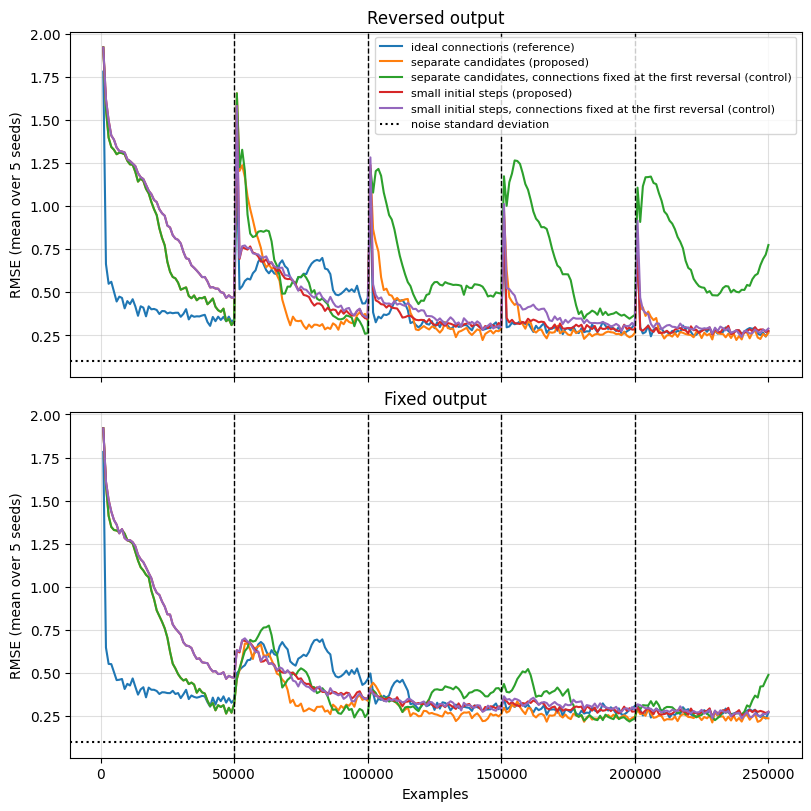

In [3]:
m.plot(curves, reversals=True)


## Inside the ideal reference

Each new hidden LTU has one shadow, a random sign on its actual edge to one output.
While the weight of that edge is smaller than 1 in size, the backward pass uses the shadow sign in place of the weight.
In the ideal reference, LTUs 0 and 2 have their shadow on the reversed output. LTUs 1 and 3 have it on the fixed output.
This is the only difference between the two pairs. The figure shows seed 2, where the common pattern is clearest.


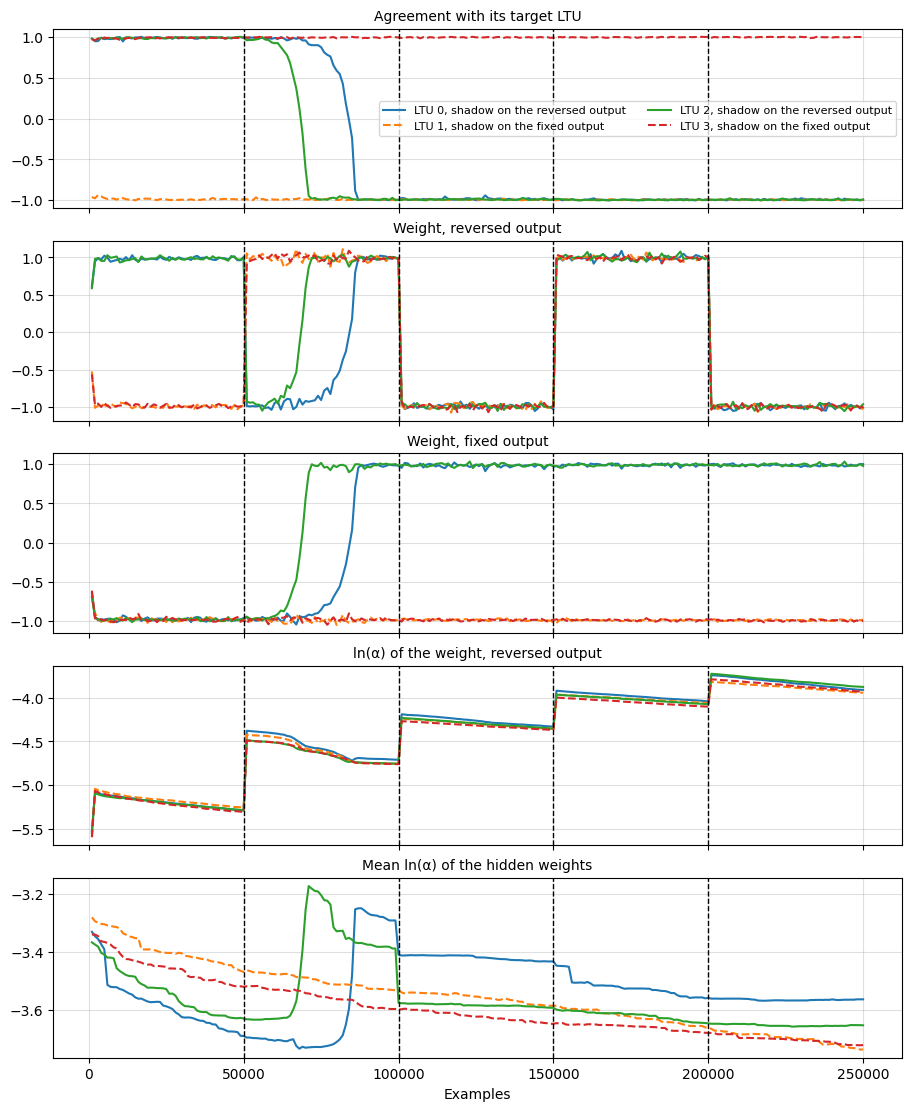

In [4]:
m.plot_units(records['ideal'], seed=2)


## All conditions

The agreement of a hidden LTU with a target LTU is the mean product of their ±1 outputs over the 1,000 examples of a window.
Just before each reversal, an LTU is tracked if its agreement with some target LTU is at least 0.9 in size.
A tracked LTU loses its feature if this agreement, with its earlier sign, falls below 0.5 before the next reversal.
The weight share is the share of the reversed output's absolute weight on hidden LTUs whose shadow is on that output.
Each line gives one value per reversal. Counts add the five seeds.


In [5]:
m.shadow_summary(records)


ideal connections (reference)
  share of reversed-output weight on LTUs with their shadow there: 0.50  0.48  0.50  0.50
  lost features, shadow on reversed output: 6/10  1/9  0/10  0/10;  on fixed output: 0/10  0/10  0/10  0/10
separate candidates (proposed)
  share of reversed-output weight on LTUs with their shadow there: 0.81  0.41  0.20  0.05
  lost features, shadow on reversed output: 18/19  9/9  3/4  1/1;  on fixed output: 1/18  0/20  0/21  0/21
separate candidates, connections fixed at the first reversal (control)
  share of reversed-output weight on LTUs with their shadow there: 0.81  0.80  0.81  0.81
  lost features, shadow on reversed output: 18/19  13/18  9/13  11/16;  on fixed output: 0/18  0/17  0/18  0/18
small initial steps (proposed)
  share of reversed-output weight on LTUs with their shadow there: 0.54  0.12  0.05  0.00
  lost features, shadow on reversed output: 9/15  2/3  2/3  0/0;  on fixed output: 0/14  0/27  0/28  0/28
small initial steps, connections fixed at th